---
format:
  html:
    embed-resources: true
jupyter: python3
execute:
  echo: false
  warning: false
---

# Block 5: Ecosystem Carbon Flux and Soil Moisture Responses to Compound Dry-and-Hot Events

**Author:** Sanglap Roy (Student 22)  
**Data source & versions:** FLUXNET Shuttle snapshot (`fluxnet_shuttle_snapshot_20261116T075027.csv`, ONEFlux processing `v1.3_r1`, `_FLUXMET_DD_` daily archives in `data/raw/`, downloaded 13 November 2026); ERA5-Land hourly time series (`reanalysis-era5-land-timeseries`, $0.1^\circ$, in `data/external/era5land/`, downloaded 24 November 2026); Dheed compound dry-and-hot event database (`LabelCube` Zarr & `EventStats`, $0.25^\circ$, `1950 – 2023`, `doi:10.5281/zenodo.14884254`, in `data/external/dheed/`, downloaded 24 November 2026).

---

## E1. Question and hypothesis

**Research Question:**  
How do compound dry-and-hot (Dheed) extreme events alter daily net ecosystem $\text{CO}_2$ exchange ($\text{NEE}$) and gross primary productivity ($\text{GPP}$) across five contrasting FLUXNET towers, and does the magnitude of carbon sink loss scale with ERA5-Land root-zone soil moisture deficits?

**Hypothesis:**  
During Dheed compound dry-and-hot events, daily $\text{NEE}$ will shift toward positive anomalies ($\Delta\text{NEE} > 0$, indicating a weakened net $\text{CO}_2$ sink or a transition to a net carbon source) and $\text{GPP}$ will decline ($\Delta\text{GPP} < 0$), with larger carbon losses at sites experiencing stronger root-zone soil moisture drawdown ($\Delta\text{swvl3} < 0$). Ecologically, simultaneous high vapor pressure deficit ($\text{VPD}$) and depleted root-zone soil water trigger stomatal closure to prevent hydraulic failure—directly suppressing photosynthetic carbon uptake ($\text{GPP}$)—while elevated temperatures sustain or enhance autotrophic and heterotrophic ecosystem respiration ($\text{RECO}$), driving $\text{NEE} = \text{RECO} - \text{GPP}$ upward.

**Suitability of the Five Towers:**  

- **Why they are a good test:** The five towers represent five distinct International Geosphere-Biosphere Programme (IGBP) vegetation classes across four continents and contrasting hydroclimates: tropical peat swamp evergreen broadleaf forest (`ID-PaD`, Indonesia), semi-arid montane evergreen needleleaf forest (`US-Vcm`, USA), temperate wet grassland (`NL-Vkp`, Netherlands), temperate cropland (`BE-Lon`, Belgium), and tropical wet-dry savanna (`AU-How`, Australia). This gradient tests whether compound drought–heat extremes consistently weaken carbon uptake across ecosystems with contrasting canopy structures, rooting depths, and baseline moisture regimes.
- **Why they are limited:** Because $n = 5$ towers provides only one site per IGBP class, vegetation type is confounded with climate zone and local hydrology, leaving zero within-biome spatial replication. In addition, `ID-PaD` ends in 2017 and lacks partitioned `GPP_NT_VUT_REF` in the daily FLUXNET product, restricting cross-tower $\Delta\text{GPP}$ comparisons to four towers.

---

## E2. Data

### Info Table

| Dataset | Variables used | Spatial resolution | Time resolution and period | Downloaded on | Script and changes | Citation |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **FLUXNET** (ONEFlux `v1.3_r1`, 2026 release) | `TIMESTAMP`, `TA_F` ($^\circ\text{C}$), `SW_IN_F` ($\text{W m}^{-2}$), `VPD_F` ($\text{hPa}$), `P_F` ($\text{mm d}^{-1}$), `LE_F_MDS` ($\text{W m}^{-2}$), `NEE_VUT_REF`, `GPP_NT_VUT_REF`, `RECO_NT_VUT_REF` ($\text{g C m}^{-2}\text{ d}^{-1}$), `NEE_VUT_REF_QC` (0–1) | Point measurement (eddy-covariance flux footprint, ~100 m – 1 km) | Daily (`FLUXMET_DD`); `ID-PaD` (2001–2017), `US-Vcm` (2007–2025), `NL-Vkp` (2014–2025), `BE-Lon` (2004–2024), `AU-How` (2002–2025) | 2026-11-13 | `scripts/get_my_towers.py --student 22` (unmodified; downloaded via FLUXNET Shuttle into `data/raw/`) | Pastorello et al. (2020), *Sci. Data* 7, 225 (`doi:10.1038/s41597-020-0534-3`); individual site citations in Section E6 |
| **ERA5-Land Hourly Time-Series** (`reanalysis-era5-land-timeseries`) | `t2m` ($\text{K} \rightarrow ^\circ\text{C}$), `stl1` (0–7 cm soil temp, $\text{K} \rightarrow ^\circ\text{C}$), `swvl1` (0–7 cm), `swvl2` (7–28 cm), `swvl3` (28–100 cm volumetric soil water, $\text{m}^3\text{ m}^{-3}$) | $0.1^\circ \times 0.1^\circ$ (~9 km grid; nearest land grid cell via CDS point service) | Hourly aggregated to daily means; matched to each tower's full record (`2001–2025`) | 2026-11-24 | `scripts/block5/01_era5land.py --student 22`; changed `YEARS_BACK` from `10` to `25` to cover 2001–2015 Dheed events, and changed variable names from `volumetric_soil_water_layer_1..3` to `volumetric_soil_water_level_1..3` to match the CDS point-timeseries API | Muñoz-Sabater et al. (2021), *ESSD* 13, 4349–4383 (`doi:10.5194/essd-13-4349-2021`); Copernicus Climate Change Service (2026) |
| **Dheed** (Connected Compound Dry-and-Hot Events) | `LabelCube` event IDs (`dheed_label`), daily binary event flag (`dheed_event`), and `EventStats` metadata | $0.25^\circ \times 0.25^\circ$ (~25–28 km ERA5 grid; exact grid cell containing each tower) | Daily, 1950–2023 (overlapped with tower records within `2001–2023`) | 2026-11-20 | `scripts/block5/03_dheed.py --student 22` (unmodified; extracts cell-level event flags from Zarr `LabelCube` rather than event bounding boxes) | Weynants et al. (2025), *ESSD* 17, 6621 (`doi:10.5194/essd-17-6621-2025`); Zenodo (`doi:10.5281/zenodo.14884254`) |

### Description of ERA5-Land and Dheed Across the Five Towers

Across the `2001–2023` Dheed overlap period, **22 unique Dheed events** (23 site-level occurrences, as synoptic European heatwave `115246` in July 2018 reached both `BE-Lon` and `NL-Vkp`) occurred at the five towers, totaling **122 event days**. Every tower experiences pronounced soil moisture depletion during Dheed events relative to non-event days: mean topsoil moisture (`swvl1`, 0–7 cm) decreases by $0.11\text{ to }0.24\text{ m}^3\text{ m}^{-3}$, and root-zone moisture (`swvl3`, 28–100 cm) decreases by $0.04\text{ to }0.14\text{ m}^3\text{ m}^{-3}$. Events cluster during major regional drought–heat episodes, including the 2014 El Niño dry spell at `ID-PaD` (18 days), the 2011–2012 and 2023 southwestern US droughts at `US-Vcm`, and the 2018 and 2022 European heatwaves at `BE-Lon` and `NL-Vkp`.

In [1]:
#| echo: false
#| warning: false
import os
import re
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from scipy import stats

if Path.cwd().name == "reports":
    os.chdir(Path.cwd().parent)

sys.path.insert(0, str(Path("scripts/block5").resolve()))
from block5_sites import get_my_sites

# Reproducible merge directly from data/raw and data/external
sites = get_my_sites("22")
RAW = Path("data/raw")
EXT = Path("data/external")
OUT = Path("data/processed")
OUT.mkdir(parents=True, exist_ok=True)

KEEP = [
    "TIMESTAMP", "TA_F", "SW_IN_F", "VPD_F", "P_F", "LE_F_MDS",
    "NEE_VUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF", "NEE_VUT_REF_QC",
]
parts = []
for zf in sorted(RAW.glob("*FLUXNET*.zip")):
    m = re.match(r"^[A-Z]+_([A-Z]{2}-[A-Za-z0-9]{3})_", zf.name)
    if not m or m.group(1) not in set(sites["site_id"]):
        continue
    with zipfile.ZipFile(zf) as z:
        dd = [n for n in z.namelist() if "FLUXMET_DD" in n]
        if not dd:
            continue
        df_site = pd.read_csv(
            z.open(dd[0]),
            na_values=[-9999, -9999.0],
            usecols=lambda c: c in KEEP,
            dtype={"TIMESTAMP": str},
        )
    df_site["date"] = pd.to_datetime(df_site.pop("TIMESTAMP"), format="%Y%m%d")
    df_site["site_id"] = m.group(1)
    parts.append(df_site)

daily = pd.concat(parts, ignore_index=True)

era_files = sorted((EXT / "era5land").glob("*_era5land_daily.csv"))
era = pd.concat((pd.read_csv(f, parse_dates=["date"]) for f in era_files), ignore_index=True)
era = era.rename(columns={c: f"era5l_{c}" for c in era.columns if c not in ("site_id", "date")})
daily = daily.merge(era, on=["site_id", "date"], how="left")

dh = pd.read_csv(EXT / "dheed" / "dheed_daily_flags_my_sites.csv", parse_dates=["date"])
daily = daily.merge(dh[["site_id", "date", "dheed_event", "dheed_label"]], on=["site_id", "date"], how="left")
daily["dheed_event"] = daily["dheed_event"].fillna(False).astype(bool)
daily = daily.merge(sites[["site_id", "igbp", "country", "first_year", "last_year"]], on="site_id", how="left")

# Quality filter (QC >= 0.50), 2001-2023 Dheed mask, & same-DOY anomalies
daily["year"] = daily["date"].dt.year
daily["doy"] = daily["date"].dt.day_of_year
daily["dheed_valid"] = np.where(daily["year"] <= 2023, daily["dheed_event"].astype(float), np.nan)

flux_cols = ["NEE_VUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF", "LE_F_MDS"]
low_qc = daily["NEE_VUT_REF_QC"].isna() | (daily["NEE_VUT_REF_QC"] < 0.50)
daily.loc[low_qc, flux_cols] = np.nan

clim_vars = [
    "NEE_VUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF",
    "TA_F", "VPD_F", "era5l_swvl1", "era5l_swvl2", "era5l_swvl3",
]
base = daily[daily["dheed_valid"] == 0]
for col in clim_vars:
    anom_col = f"{col}_anom"
    daily[anom_col] = np.nan
    for site, g_site in daily.groupby("site_id"):
        b_site = base[base["site_id"] == site]
        doy_means = {}
        for d in range(1, 367):
            diff = np.abs(b_site["doy"] - d)
            diff = np.minimum(diff, 365 - diff)
            doy_means[d] = b_site.loc[diff <= 15, col].mean()
        daily.loc[g_site.index, anom_col] = g_site[col] - g_site["doy"].map(doy_means)

SITE_ORDER = ["ID-PaD", "US-Vcm", "NL-Vkp", "BE-Lon", "AU-How"]
valid = daily[daily["dheed_valid"].notna()].copy()
events_all = valid[valid["dheed_valid"] == 1].copy()
normal_all = valid[valid["dheed_valid"] == 0].copy()

rows = []
for s in SITE_ORDER:
    g_all = valid[valid["site_id"] == s]
    g_ev = events_all[events_all["site_id"] == s]
    g_no = normal_all[normal_all["site_id"] == s]
    meta = sites[sites["site_id"] == s].iloc[0]
    rows.append({
        "Site": s,
        "IGBP": meta["igbp"],
        "Country": meta["country"],
        "Dheed Overlap": f"{int(g_all['year'].min())}–{int(g_all['year'].max())}",
        "Events": int(g_ev["dheed_label"].nunique()),
        "Event Days (Total / QC≥0.5)": f"{len(g_ev)} / {int(g_ev['NEE_VUT_REF'].notna().sum())}",
        "Normal Days (QC≥0.5)": int(g_no["NEE_VUT_REF"].notna().sum()),
        "swvl1 Norm / Event (m³ m⁻³)": f"{g_no['era5l_swvl1'].mean():.3f} / {g_ev['era5l_swvl1'].mean():.3f}",
        "swvl3 Norm / Event (m³ m⁻³)": f"{g_no['era5l_swvl3'].mean():.3f} / {g_ev['era5l_swvl3'].mean():.3f}",
        "Mean ΔNEE (g C m⁻² d⁻¹)": round(g_ev["NEE_VUT_REF_anom"].mean(), 2),
        "Mean ΔGPP (g C m⁻² d⁻¹)": round(g_ev["GPP_NT_VUT_REF_anom"].mean(), 2),
    })

table1 = pd.DataFrame(rows)
display(HTML(table1.to_html(index=False)))

display(HTML("""<style>
.cell-output-display figure,
.cell-output-display .figure,
.quarto-figure {
  display: block !important;
  width: 100% !important;
  max-width: 100% !important;
}
.cell-output-display img {
  display: block !important;
  width: 100% !important;
  max-width: 100% !important;
  height: auto !important;
}
</style>"""))



==> Your towers:
site_id igbp country        lat         lon  first_year  last_year
 ID-PaD  EBF      ID  -2.346071  114.036410        2001       2017
 US-Vcm  ENF      US  35.888400 -106.532100        2007       2025
 NL-Vkp  GRA      NL  51.980934    5.618825        2014       2025
 BE-Lon  CRO      BE  50.551620    4.746234        2004       2024
 AU-How  WSA      AU -12.495200  131.150050        2002       2025


Site,IGBP,Country,Dheed Overlap,Events,Event Days (Total / QC≥0.5),Normal Days (QC≥0.5),swvl1 Norm / Event (m³ m⁻³),swvl3 Norm / Event (m³ m⁻³),Mean ΔNEE (g C m⁻² d⁻¹),Mean ΔGPP (g C m⁻² d⁻¹)
ID-PaD,EBF,ID,2001–2017,4,29 / 8,4398,0.351 / 0.114,0.355 / 0.220,0.75,NaN
US-Vcm,ENF,US,2007–2023,8,53 / 38,5107,0.310 / 0.163,0.312 / 0.271,0.72,-1.05
NL-Vkp,GRA,NL,2014–2023,2,8 / 8,3484,0.325 / 0.134,0.318 / 0.244,0.70,0.90
BE-Lon,CRO,BE,2004–2023,5,19 / 19,6881,0.342 / 0.169,0.326 / 0.213,3.48,-4.60
AU-How,WSA,AU,2002–2023,4,13 / 13,7273,0.261 / 0.148,0.282 / 0.194,0.76,-2.22


*Table 1. Summary of Dheed compound dry-and-hot events, ERA5-Land topsoil (`swvl1`, 0–7 cm) and root-zone (`swvl3`, 28–100 cm) volumetric soil water content, and quality-filtered ($\text{QC} \ge 0.50$) carbon flux anomalies across the five FLUXNET towers (`2001–2023`).*

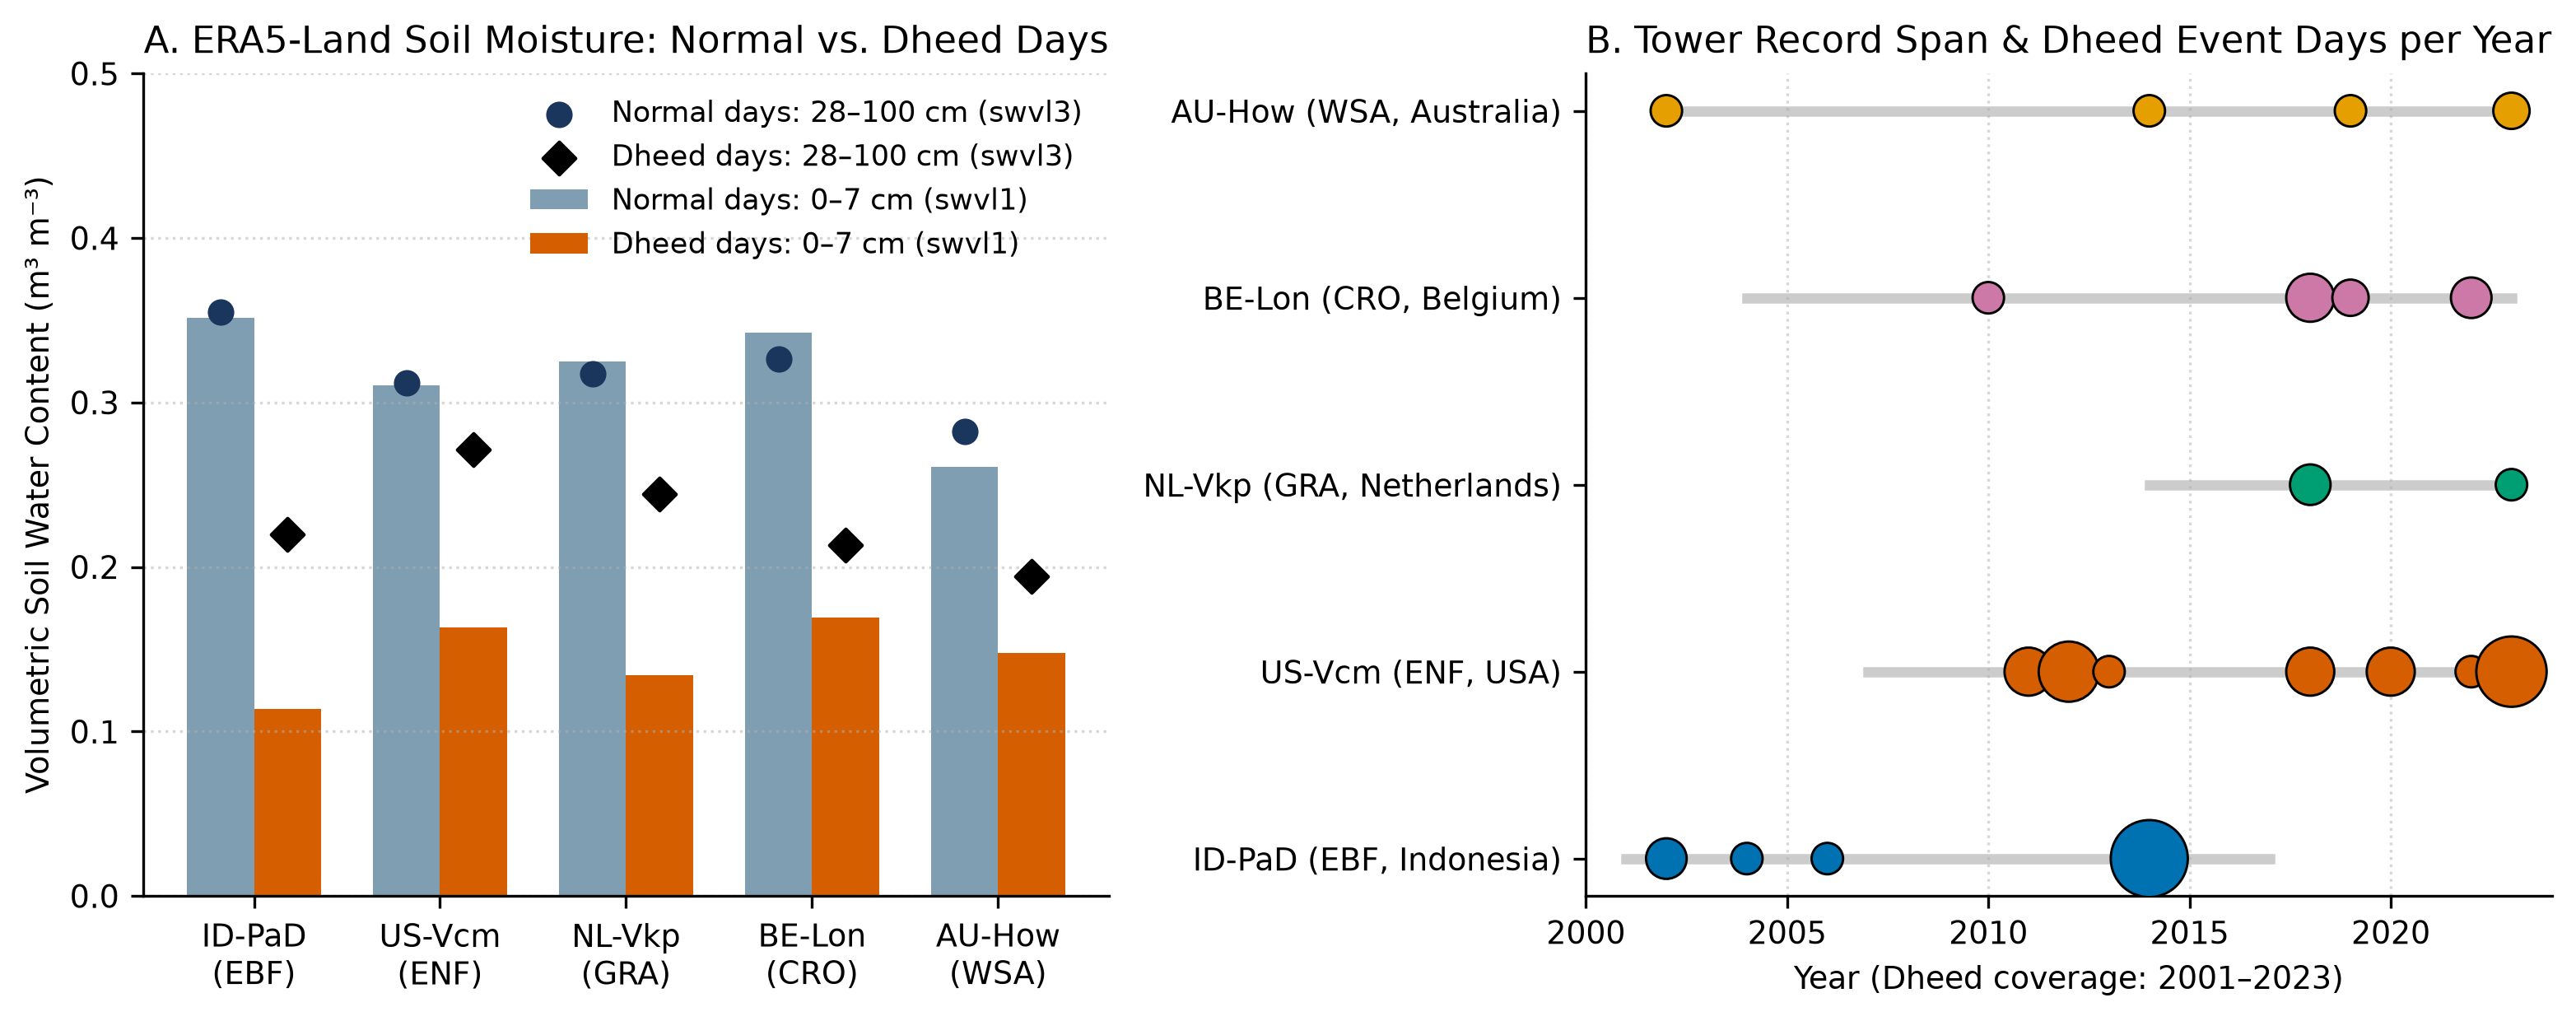

In [2]:
#| out-width: 100%
#| echo: false
#| warning: false
SITE_STYLE = {
    "ID-PaD": {"color": "#0072B2", "marker": "o", "label": "ID-PaD (EBF, Indonesia)"},
    "US-Vcm": {"color": "#D55E00", "marker": "s", "label": "US-Vcm (ENF, USA)"},
    "NL-Vkp": {"color": "#009E73", "marker": "^", "label": "NL-Vkp (GRA, Netherlands)"},
    "BE-Lon": {"color": "#CC79A7", "marker": "D", "label": "BE-Lon (CRO, Belgium)"},
    "AU-How": {"color": "#E69F00", "marker": "v", "label": "AU-How (WSA, Australia)"},
}

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2), dpi=150)

x = np.arange(len(SITE_ORDER))
w = 0.36
norm_s1 = [normal_all[normal_all["site_id"] == s]["era5l_swvl1"].mean() for s in SITE_ORDER]
ev_s1 = [events_all[events_all["site_id"] == s]["era5l_swvl1"].mean() for s in SITE_ORDER]
norm_s3 = [normal_all[normal_all["site_id"] == s]["era5l_swvl3"].mean() for s in SITE_ORDER]
ev_s3 = [events_all[events_all["site_id"] == s]["era5l_swvl3"].mean() for s in SITE_ORDER]

ax1.bar(x - w / 2, norm_s1, width=w, color="#7F9EB2", label="Normal days: 0–7 cm (swvl1)")
ax1.bar(x + w / 2, ev_s1, width=w, color="#D55E00", label="Dheed days: 0–7 cm (swvl1)")
ax1.scatter(x - w / 2, norm_s3, color="#1B365D", zorder=5, s=45, label="Normal days: 28–100 cm (swvl3)")
ax1.scatter(x + w / 2, ev_s3, color="#000000", marker="D", zorder=5, s=45, label="Dheed days: 28–100 cm (swvl3)")

ax1.set_xticks(x)
ax1.set_xticklabels([f"{s}\n({sites.loc[sites['site_id']==s, 'igbp'].values[0]})" for s in SITE_ORDER])
ax1.set_ylabel("Volumetric Soil Water Content (m³ m⁻³)")
ax1.set_title("A. ERA5-Land Soil Moisture: Normal vs. Dheed Days")
ax1.set_ylim(0, 0.50)
ax1.legend(frameon=False, fontsize=8.5, loc="upper right")
ax1.grid(axis="y", linestyle=":", alpha=0.5)

for idx, s in enumerate(SITE_ORDER):
    g_s = valid[valid["site_id"] == s]
    yr_span = g_s["year"].unique()
    ax2.plot([yr_span.min(), yr_span.max()], [idx, idx], color="#CCCCCC", linewidth=3, zorder=1)
    ev_yr = events_all[events_all["site_id"] == s].groupby("year").size()
    ax2.scatter(
        ev_yr.index,
        np.repeat(idx, len(ev_yr)),
        s=ev_yr.values * 28,
        color=SITE_STYLE[s]["color"],
        edgecolors="black",
        linewidth=0.7,
        zorder=3,
    )

ax2.set_yticks(range(len(SITE_ORDER)))
ax2.set_yticklabels([SITE_STYLE[s]["label"] for s in SITE_ORDER])
ax2.set_xlabel("Year (Dheed coverage: 2001–2023)")
ax2.set_title("B. Tower Record Span & Dheed Event Days per Year")
ax2.set_xlim(2000, 2024)
ax2.grid(axis="x", linestyle=":", alpha=0.5)

fig1.tight_layout()
plt.show()

**Figure 1 Caption:** *(A)* Mean ERA5-Land volumetric soil water content ($\text{m}^3\text{ m}^{-3}$) in the topsoil (`swvl1`, 0–7 cm, bars) and root zone (`swvl3`, 28–100 cm, markers) during non-event baseline days versus Dheed compound dry-and-hot event days (`2001–2023`). *(B)* Active observation span of each FLUXNET tower within the Dheed period (grey horizontal bars) and annual number of Dheed event days (circle area proportional to event days per year; total $n = 122$ event days across $22$ unique events).

---

## E3. Methods

### Download

- **FLUXNET:** Daily eddy-covariance files (`FLUXMET_DD`) for Student 22 (`ID-PaD`, `US-Vcm`, `NL-Vkp`, `BE-Lon`, `AU-How`) were downloaded from the FLUXNET Shuttle into `data/raw/` via `scripts/get_my_towers.py --student 22`.
- **Dheed:** `scripts/block5/03_dheed.py --student 22` queried the Zenodo Zarr `LabelCube` (37 MB) and `EventStats` CSV (14 MB) (`doi:10.5281/zenodo.14884254`), saving `dheed_events_my_sites.csv` and `dheed_daily_flags_my_sites.csv` in `data/external/dheed/`.
- **ERA5-Land:** `scripts/block5/01_era5land.py --student 22` downloaded hourly point time series from the Copernicus Climate Data Store (CDS) `reanalysis-era5-land-timeseries` API via `cdsapi`. Two issues encountered during execution were resolved:
  1. Corrupted package metadata in the local Python `.venv` (`cdsapi`/`idna` and `matplotlib`/`cycler`) caused `ModuleNotFoundError` and `PackageNotFoundError`, which were fixed by removing the broken folders and running clean `--no-cache-dir` reinstalls.
  2. `YEARS_BACK` was increased from `10` to `25` so early tower years (`2001–2015`, including the 2014 El Niño event at `ID-PaD` and 2011–2012 droughts at `US-Vcm`) were covered, and the CDS request variable names were updated from `volumetric_soil_water_layer_1..3` to `volumetric_soil_water_level_1..3` after CDS silently omitted `layer_*` variables.

### Extraction

All spatial extraction was performed in geographic coordinates (WGS84, `EPSG:4326`) at each tower's exact coordinates (`ID-PaD`: $-2.3461^\circ, 114.0364^\circ$; `US-Vcm`: $35.8884^\circ, -106.5321^\circ$; `NL-Vkp`: $51.9809^\circ, 5.6188^\circ$; `BE-Lon`: $50.5516^\circ, 4.7462^\circ$; `AU-How`: $-12.4952^\circ, 131.1501^\circ$). For ERA5-Land, the CDS point-timeseries service extracted the nearest $0.1^\circ$ land grid cell center to each tower. For Dheed, `03_dheed.py` extracted the exact $0.25^\circ$ ERA5 grid cell containing each tower from the Zarr `LabelCube` rather than using `EventStats` bounding boxes, avoiding false positives (particularly for European events crossing the $0^\circ$ meridian whose bounding boxes span $0^\circ\text{--}359.75^\circ$).

### Processing

- **Common time step and units:** Hourly ERA5-Land time series were averaged to daily UTC dates (`date`) and merged with FLUXNET `FLUXMET_DD` daily tables via `scripts/block5/09_merge.py` (`33,969` tower-days across all five sites). Air and soil temperatures were converted from $\text{K}$ to $^\circ\text{C}$; volumetric soil moisture (`swvl1` 0–7 cm, `swvl2` 7–28 cm, `swvl3` 28–100 cm) is in $\text{m}^3\text{ m}^{-3}$; carbon fluxes (`NEE_VUT_REF`, `GPP_NT_VUT_REF`, `RECO_NT_VUT_REF`) are in $\text{g C m}^{-2}\text{ d}^{-1}$ (negative $\text{NEE}$ denotes net ecosystem $\text{CO}_2$ uptake; positive $\text{NEE}$ denotes net $\text{CO}_2$ release).
- **Missing values, quality filters, and baselines:** In `scripts/block5/10_prepare_q3.py`, FLUXNET `-9999` sentinels were parsed as `NaN` (`0` sentinels remaining) without cross-tower gap-filling. Flux observations with low measurement/gap-fill confidence (`NEE_VUT_REF_QC < 0.50` or `NaN`) were masked to `NaN`, retaining **86 of 122 Dheed event days** (`AU-How`: 13/13, `BE-Lon`: 19/19, `NL-Vkp`: 8/8, `US-Vcm`: 38/53, `ID-PaD`: 8/29). Because the Dheed dataset ends on `2023-12-31`, `2024–2025` observations were assigned `dheed_valid = NaN` so unlabelled days were excluded from the non-event baseline. Daily anomalies ($\Delta\text{NEE}$, $\Delta\text{GPP}$, $\Delta\text{swvl1}$, $\Delta\text{swvl3}$) were computed relative to each site's same-DOY ($\pm 15\text{ day}$ circular calendar window) non-event baseline across `2001–2023`.

### Analysis

In `scripts/block5/11_analyze_q3.py`, because consecutive days within a multi-day heatwave are temporally autocorrelated, daily anomalies were first averaged within each unique `(site_id, dheed_label)` event ($n = 19$ QC-filtered events out of $22$ unique events; $n = 86$ QC-filtered event days vs. $27,143$ normal baseline days) and then averaged to one mean per tower ($n = 5$ towers). Across the $n = 5$ tower means, we calculated the cross-tower mean $\pm$ SD of $\Delta\text{NEE}$ and $\Delta\text{GPP}$, a one-sample $t$-test against $\Delta\text{NEE} = 0$, and an ordinary least-squares (OLS) regression of $\Delta\text{NEE}$ on root-zone soil moisture anomaly ($\Delta\text{swvl3}$), supplemented by the event-level Pearson correlation ($n = 19$).

---

## E4. Results

- **Primary Summary Statistic (Cross-tower mean $\Delta\text{NEE}$):** **$+1.22 \pm 1.27\text{ g C m}^{-2}\text{ d}^{-1}$** (mean $\pm$ SD across $n = 5$ towers; one-sample $t = 2.15$, $p = 0.098$).
- **Photosynthetic Suppression (Cross-tower mean $\Delta\text{GPP}$):** **$-1.77\text{ g C m}^{-2}\text{ d}^{-1}$** ($n = 4$ towers with partitioned GPP).
- **Soil Moisture Sensitivity ($\Delta\text{NEE} \sim \Delta\text{swvl3}$):** Cross-tower OLS slope $= -14.82\text{ g C m}^{-2}\text{ d}^{-1}\text{ per m}^3\text{ m}^{-3}$ ($r = -0.32$, $p = 0.603$, $n = 5$ towers); event-level correlation $r = -0.30$, $p = 0.219$ ($n = 19$ QC-filtered events).
- **Sample Size ($n$):** $n = 5$ towers (`2001–2023` overlap), $n = 22$ unique Dheed events ($n = 19$ with $\text{QC} \ge 0.50$), and $n = 122$ total event days ($n = 86$ with $\text{QC} \ge 0.50$, compared against $n = 27,143$ normal baseline days).

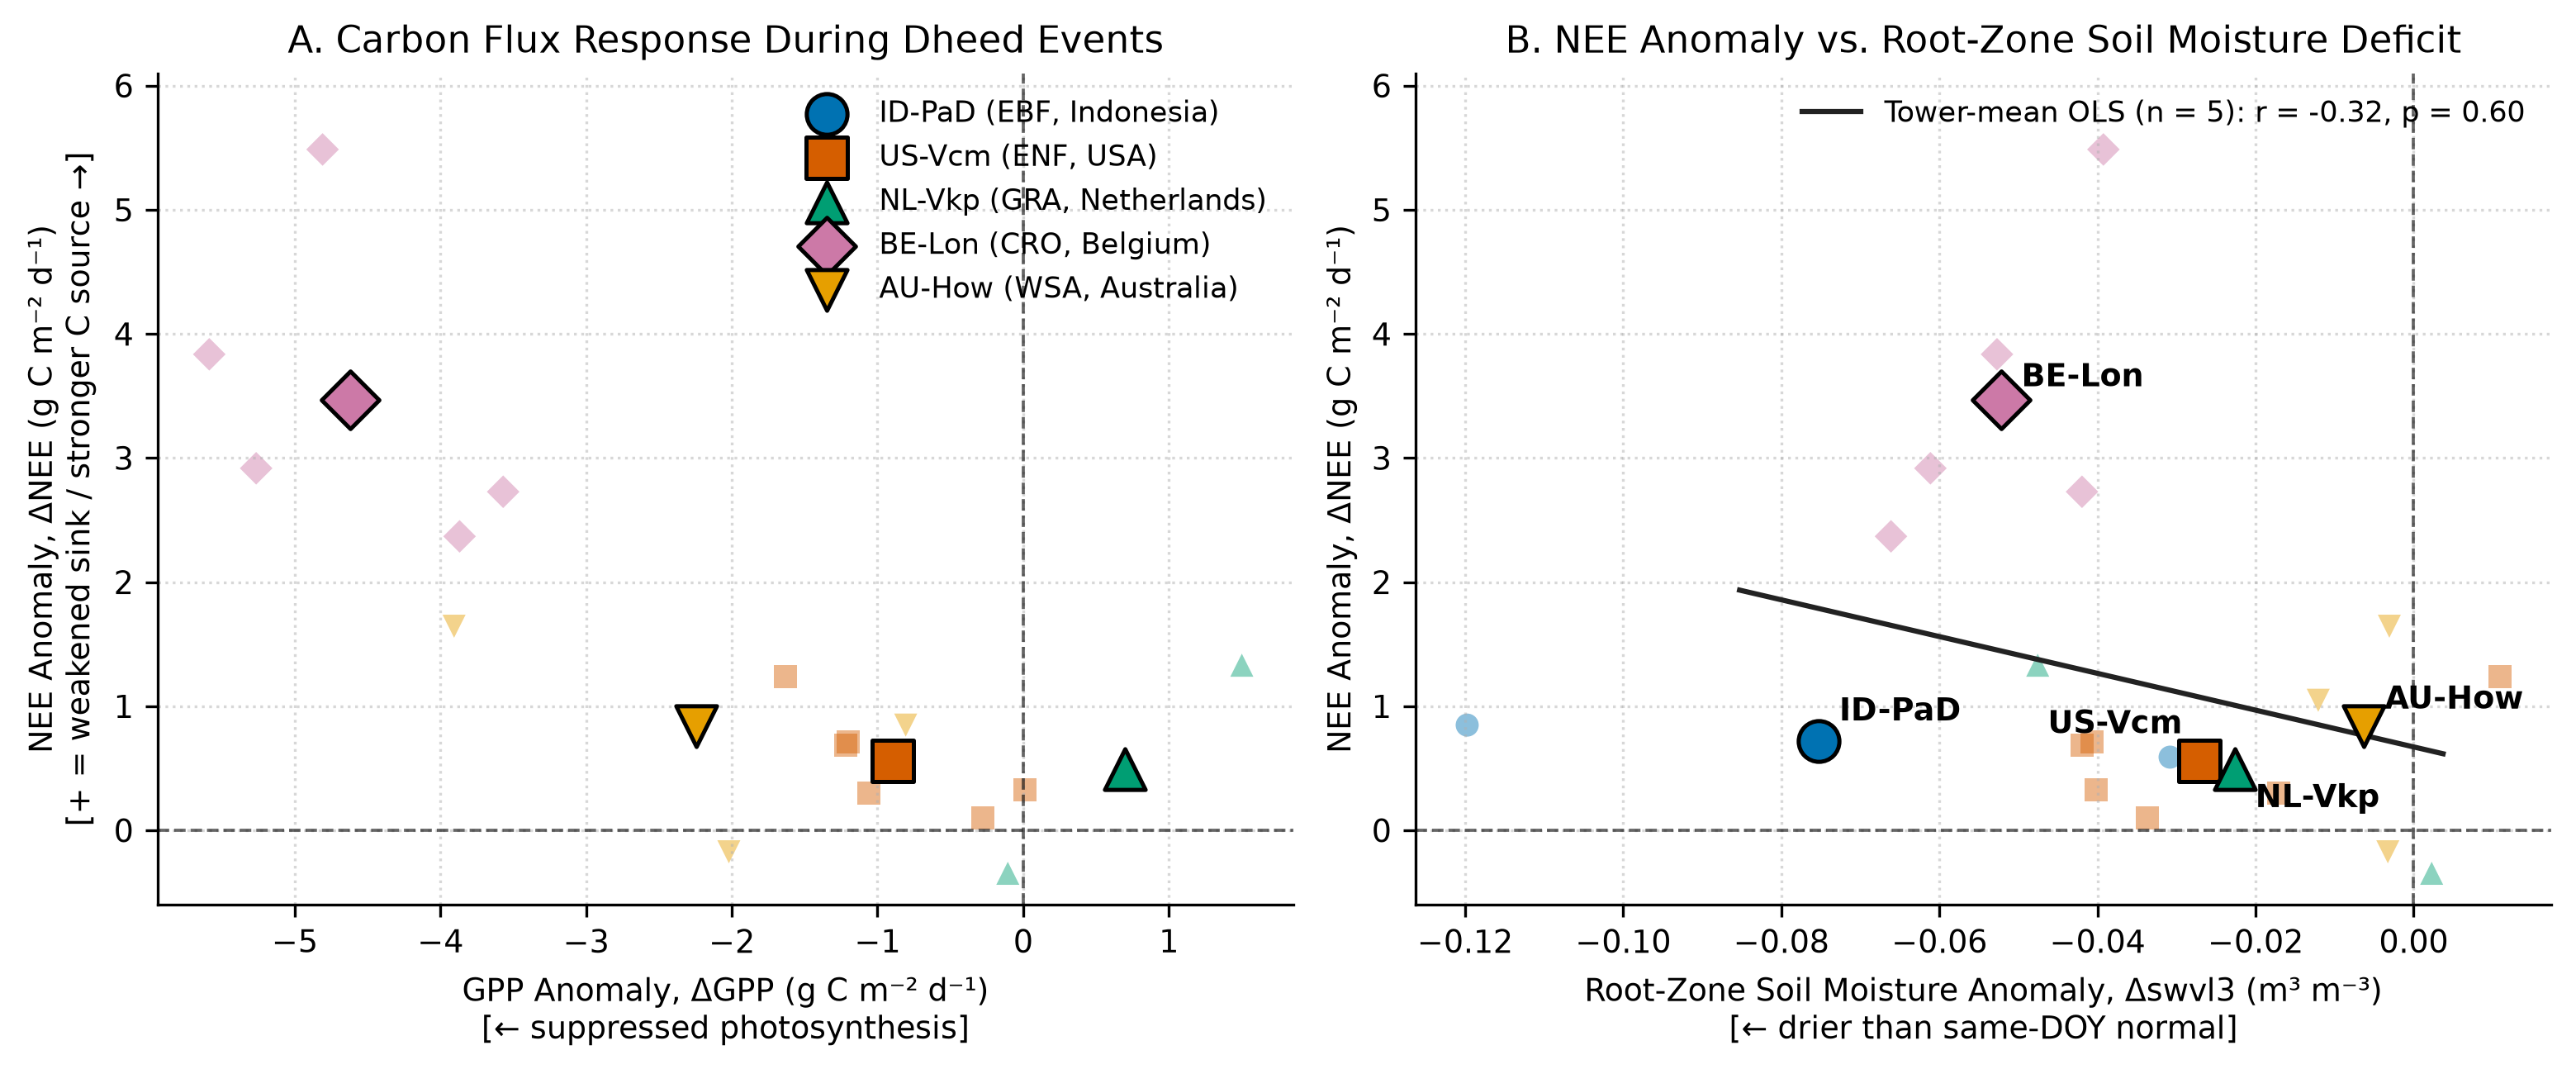

In [3]:
#| out-width: 100%
#| echo: false
#| warning: false
ev_level = (
    events_all.groupby(["site_id", "igbp", "dheed_label"], as_index=False)
    .agg(
        n_days=("date", "count"),
        n_qc_days=("NEE_VUT_REF", lambda x: x.notna().sum()),
        dNEE=("NEE_VUT_REF_anom", "mean"),
        dGPP=("GPP_NT_VUT_REF_anom", "mean"),
        dSWVL3=("era5l_swvl3_anom", "mean"),
    )
)

tower_level = (
    ev_level.dropna(subset=["dNEE"])
    .groupby(["site_id", "igbp"], as_index=False)
    .agg(
        n_events=("dheed_label", "count"),
        dNEE=("dNEE", "mean"),
        dGPP=("dGPP", "mean"),
        dSWVL3=("dSWVL3", "mean"),
    )
)

reg_t = stats.linregress(tower_level["dSWVL3"], tower_level["dNEE"])

fig2, (bx1, bx2) = plt.subplots(1, 2, figsize=(10.5, 4.4), dpi=150)

bx1.axhline(0, color="black", linestyle="--", linewidth=0.9, alpha=0.6)
bx1.axvline(0, color="black", linestyle="--", linewidth=0.9, alpha=0.6)

for s in SITE_ORDER:
    st = SITE_STYLE[s]
    sub_ev = ev_level[ev_level["site_id"] == s].dropna(subset=["dGPP", "dNEE"])
    bx1.scatter(sub_ev["dGPP"], sub_ev["dNEE"], color=st["color"], marker=st["marker"], alpha=0.45, s=45, edgecolors="none")
    sub_tw = tower_level[tower_level["site_id"] == s]
    bx1.scatter(
        sub_tw["dGPP"], sub_tw["dNEE"],
        color=st["color"], marker=st["marker"], s=140, edgecolors="black", linewidth=1.2,
        label=st["label"], zorder=5
    )

bx1.set_xlabel("GPP Anomaly, ΔGPP (g C m⁻² d⁻¹)\n[← suppressed photosynthesis]")
bx1.set_ylabel("NEE Anomaly, ΔNEE (g C m⁻² d⁻¹)\n[+ = weakened sink / stronger C source →]")
bx1.set_title("A. Carbon Flux Response During Dheed Events")
bx1.set_ylim(-0.6, 6.1)
bx1.legend(frameon=False, fontsize=8.5, loc="upper right")
bx1.grid(linestyle=":", alpha=0.5)

bx2.axhline(0, color="black", linestyle="--", linewidth=0.9, alpha=0.6)
bx2.axvline(0, color="black", linestyle="--", linewidth=0.9, alpha=0.6)

offsets = {"ID-PaD": (6, 6), "US-Vcm": (-44, 8), "NL-Vkp": (6, -11), "BE-Lon": (6, 4), "AU-How": (6, 5)}
for s in SITE_ORDER:
    st = SITE_STYLE[s]
    sub_ev = ev_level[ev_level["site_id"] == s].dropna(subset=["dSWVL3", "dNEE"])
    bx2.scatter(sub_ev["dSWVL3"], sub_ev["dNEE"], color=st["color"], marker=st["marker"], alpha=0.45, s=45, edgecolors="none")
    sub_tw = tower_level[tower_level["site_id"] == s]
    bx2.scatter(
        sub_tw["dSWVL3"], sub_tw["dNEE"],
        color=st["color"], marker=st["marker"], s=140, edgecolors="black", linewidth=1.2, zorder=5
    )
    bx2.annotate(
        s, (sub_tw["dSWVL3"].values[0], sub_tw["dNEE"].values[0]),
        xytext=offsets[s], textcoords="offset points", fontsize=9, fontweight="bold"
    )

x_grid = np.linspace(tower_level["dSWVL3"].min() - 0.01, tower_level["dSWVL3"].max() + 0.01, 50)
bx2.plot(
    x_grid, reg_t.intercept + reg_t.slope * x_grid,
    color="#222222", linestyle="-", linewidth=1.5,
    label=f"Tower-mean OLS (n = 5): r = {reg_t.rvalue:.2f}, p = {reg_t.pvalue:.2f}"
)

bx2.set_xlabel("Root-Zone Soil Moisture Anomaly, Δswvl3 (m³ m⁻³)\n[← drier than same-DOY normal]")
bx2.set_ylabel("NEE Anomaly, ΔNEE (g C m⁻² d⁻¹)")
bx2.set_title("B. NEE Anomaly vs. Root-Zone Soil Moisture Deficit")
bx2.set_ylim(-0.6, 6.1)
bx2.legend(frameon=False, fontsize=8.5, loc="upper right")
bx2.grid(linestyle=":", alpha=0.5)

fig2.tight_layout()
plt.show()

**Figure 2 Caption:** *(A)* Daily net ecosystem exchange anomaly ($\Delta\text{NEE}$, $\text{g C m}^{-2}\text{ d}^{-1}$) versus gross primary productivity anomaly ($\Delta\text{GPP}$, $\text{g C m}^{-2}\text{ d}^{-1}$) during Dheed events relative to same-DOY ($\pm 15\text{ day}$) non-event baselines (`2001–2023`, $\text{QC} \ge 0.50$). Faint symbols show individual Dheed event means ($n = 19$ events across $86$ QC-filtered event days) and bold outlined symbols show tower means ($n = 5$ towers; note `ID-PaD` lacks daily partitioned `GPP_NT_VUT_REF`). *(B)* $\Delta\text{NEE}$ versus ERA5-Land root-zone soil moisture anomaly ($\Delta\text{swvl3}$, 28–100 cm, $\text{m}^3\text{ m}^{-3}$), showing the cross-tower OLS fit ($\text{slope} = -14.82\text{ g C m}^{-2}\text{ d}^{-1}\text{ per m}^3\text{ m}^{-3}$, $r = -0.32$, $p = 0.603$, $n = 5$ towers). Across all five towers, compound dry-and-hot events weaken the net carbon sink by a mean of **$\Delta\text{NEE} = +1.22 \pm 1.27\text{ g C m}^{-2}\text{ d}^{-1}$**.

---

## E5. Discussion

The results support our directional hypothesis across all five towers, as every site shows a positive mean $\Delta\text{NEE}$ anomaly during Dheed events (cross-tower mean $+1.22 \pm 1.27\text{ g C m}^{-2}\text{ d}^{-1}$, $n = 5$ towers; $t = 2.15$, $p = 0.098$), confirming that compound dry-and-hot extremes consistently weaken net ecosystem $\text{CO}_2$ uptake. Cropland `BE-Lon` ($\Delta\text{NEE} = +3.48\text{ g C m}^{-2}\text{ d}^{-1}$, $\Delta\text{GPP} = -4.60\text{ g C m}^{-2}\text{ d}^{-1}$) and savanna `AU-How` ($\Delta\text{GPP} = -2.22\text{ g C m}^{-2}\text{ d}^{-1}$) strongly follow the hypothesized photosynthetic suppression mechanism, whereas wet grassland `NL-Vkp` diverges by slightly increasing $\text{GPP}$ ($+0.90\text{ g C m}^{-2}\text{ d}^{-1}$) under sunny conditions while still shifting toward a weaker carbon sink ($\Delta\text{NEE} = +0.70\text{ g C m}^{-2}\text{ d}^{-1}$) due to heat-enhanced respiration. Across towers, however, the linear slope of $\Delta\text{NEE}$ against root-zone soil moisture deficit ($\Delta\text{swvl3}$) is weak ($r = -0.32$, $p = 0.603$), showing that vegetation functional traits strongly mediate drought sensitivity. This scatter is amplified by spatial scale mismatch between tower flux footprints (~$100\text{ m}$ to $1\text{ km}$) and the coarse grids of ERA5-Land ($0.1^\circ$, ~$9\text{ km}$) and Dheed ($0.25^\circ$, ~$25\text{--}28\text{ km}$). Because a $9\text{--}28\text{ km}$ reanalysis cell averages over surrounding land covers and drainage regimes, grid-cell soil moisture can misrepresent root-zone water availability inside the tower footprint—for example at tropical peat swamp `ID-PaD`, where ERA5-Land shows severe drying ($\Delta\text{swvl3} = -0.075\text{ m}^3\text{ m}^{-3}$) yet deep roots tapping groundwater buffer carbon loss ($\Delta\text{NEE} = +0.75\text{ g C m}^{-2}\text{ d}^{-1}$). The first major limitation is the small sample size ($n = 5$ towers and $n = 19$ QC-filtered events), which confounds biome type with climate and provides low statistical power for cross-tower regressions. The second limitation is flux data loss during extreme weather under quality filtering, which reduced `ID-PaD` from $29$ to $8$ usable event days and left partitioned `GPP_NT_VUT_REF` missing at `ID-PaD`. With more time and data, we would pool all available FLUXNET sites within each IGBP biome to separate vegetation sensitivity from local climate and analyze $7\text{--}30\text{ day}$ post-event windows to quantify carbon sink recovery.

---

## E6. Data and citations

### FLUXNET Site Citations

- **ID-PaD:** Hirano, T., Ohkubo, S. (2026). Fluxnet Archive Product from Palangkaraya Drained forest, 2001–2017, FLUXNET, [https://hdl.handle.net/11676/RaxQP0fkOSWCXKIIhi7Bnevj](https://hdl.handle.net/11676/RaxQP0fkOSWCXKIIhi7Bnevj)
- **US-Vcm:** Marcy Litvak (2026), AmeriFlux FLUXNET-1F US-Vcm Valles Caldera Mixed Conifer, Ver. v1.3_r1 (2007–2025), AmeriFlux AMP, (Dataset). [https://doi.org/10.17190/AMF/2229391](https://doi.org/10.17190/AMF/2229391)
- **NL-Vkp:** Barten, J., Hartogensis, O., Heusinkveld, B. (2026). Fluxnet Archive Product from Veenkampen, 2014–2025, FLUXNET, [https://hdl.handle.net/11676/NjPFe8mMhEmbG6xHDtKSw-sx](https://hdl.handle.net/11676/NjPFe8mMhEmbG6xHDtKSw-sx)
- **BE-Lon:** Dumont, B., Heinesch, B., Bodson, B., Bogaerts, G., Chopin, H., De Ligne, A., Demoulin, L., Douxfils, B., Engelmann, T., Faurès, A., Longdoz, B., Manise, T., Orgun, A., Piret, A., Thyrion, T. (2026). Fluxnet Archive Product from Lonzee, 2004–2024, FLUXNET, [https://hdl.handle.net/11676/1u2xQ5XcQoX0j2wJiZcyDP3M](https://hdl.handle.net/11676/1u2xQ5XcQoX0j2wJiZcyDP3M)
- **AU-How:** Beringer, J., Hutley, L., Northwood, M. (2026): Howard Springs FLUXNET Release 2026_r1. Version 2026_r1. Terrestrial Ecosystem Research Network (TERN). (Dataset).

### Synthesis & External Dataset Citations

- **FLUXNET2015 / ONEFlux Processing:** Pastorello, G., Trotta, C., Canfora, E., et al. (2020). The FLUXNET2015 dataset and the ONEFlux processing pipeline for eddy covariance data. *Scientific Data*, 7, 225. [https://doi.org/10.1038/s41597-020-0534-3](https://doi.org/10.1038/s41597-020-0534-3)
- **ERA5-Land:** Muñoz-Sabater, J., Dutra, E., Agustí-Panareda, A., Albergel, C., Arduini, G., Balsamo, G., Boussetta, S., Choulga, M., Harrigan, S., Hersbach, H., Martens, B., Miralles, D. G., Piles, M., Rodríguez-Fernández, N. J., Zsoter, E., Buontempo, C., & Thépaut, J.-N. (2021). ERA5-Land: a state-of-the-art global reanalysis dataset for land applications. *Earth System Science Data*, 13, 4349–4383. [https://doi.org/10.5194/essd-13-4349-2021](https://doi.org/10.5194/essd-13-4349-2021). Contains modified Copernicus Climate Change Service information (2026).
- **Dheed:** Weynants, M., Ji, C., Mahecha, M. D., & Linscheid, N. (2025). Dheed: a global database of connected compound dry and hot extreme events. *Earth System Science Data*, 17, 6621. [https://doi.org/10.5194/essd-17-6621-2025](https://doi.org/10.5194/essd-17-6621-2025); Dataset on Zenodo: [https://doi.org/10.5281/zenodo.14884254](https://doi.org/10.5281/zenodo.14884254)

### FLUXNET Acknowledgement

> FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service.